# Kernel shapes and mixtures

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/12_kernel_shapes.ipynb)

By default every factor is a Gaussian (a radial basis function, `kernel='rbf'`). `htfa.TFA`, `htfa.HTFA` and `htfa.fit` take two more options:

- `kernel`: the profile of a factor, as a function of `z = ||r - c||^2 / w` (center `c`, width `w`):
  - `'rbf'`: `exp(-z)`;
  - `'laplace'`: `exp(eps - sqrt(z + eps^2))` with `eps = 0.1`, a sharp peak with exponential tails `exp(-r / sqrt(w))`, rounded within about `0.1 sqrt(w)` of the center so that it can be differentiated there;
  - `'mexican_hat'`: `(1 - 2z/D) exp(-z)` in `D` dimensions, the negative Laplacian of a Gaussian: a positive center within `r = sqrt(D w / 2)` and a negative surround, with integral 0.
- `n_components` (default 1): with `M > 1`, each factor is a mixture of `M` components of that shape, each with its own center and width, plus mixing weights (a softmax, so they are positive and sum to 1) that are fitted together with them. The factor's time series are fitted for the whole mixture, as for a single component.

This tutorial

1. draws the shapes in 1D and 2D;
2. generates synthetic data from each shape (and from a two-component RBF mixture);
3. fits every kernel to every dataset with the same number of factors, `K`, and compares the variance explained (a generator x fitted-kernel grid);
4. repeats the comparison over `K` and over `n_components`.

The data are 2D (a 30 x 30 grid) so that every fit takes well under a second.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

In [2]:
import time
import warnings

import numpy as np
from sklearn.exceptions import ConvergenceWarning

import htfa
from htfa.tfa import component_factors

plt = htfa.require("matplotlib.pyplot")
warnings.simplefilter("ignore", ConvergenceWarning)
start_time = time.perf_counter()
KERNELS = ("rbf", "laplace", "mexican_hat")

## 1. What the shapes look like

Each profile is 1 at its center. The 1D panel plots one factor of width `w = 1` against the distance `r` (in units of `sqrt(w)`) in 2D. The Laplace profile has a narrower peak and heavier tails than the Gaussian; the mexican hat crosses 0 at `r = 1` (in 2D) and has a shallow negative surround. The mixture on the right has two RBF components: one at the center with weight 0.6 and width 1, and one 1.2 units away with weight 0.4 and width 0.3.

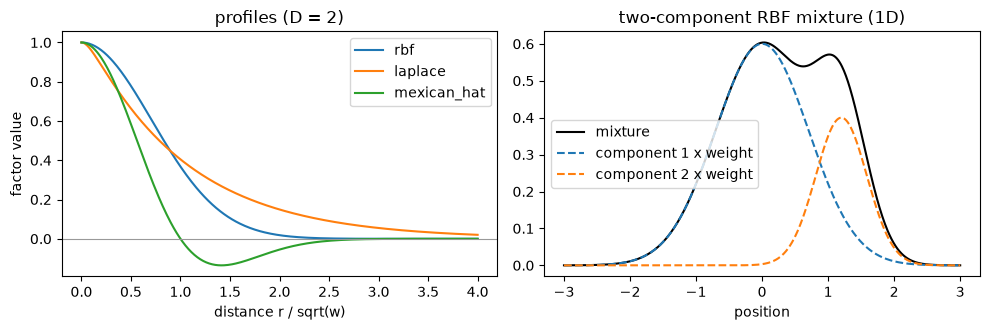

In [3]:
r = np.linspace(0, 4, 401)
colors = {"rbf": "C0", "laplace": "C1", "mexican_hat": "C2"}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
# One factor of width 1 at the origin, evaluated along a line in 2D.
line = np.column_stack([r, np.zeros_like(r)])
for name in KERNELS:
    profile = component_factors(line, [[[0.0, 0.0]]], [[1.0]], [[1.0]], name)
    axes[0].plot(r, profile[:, 0], color=colors[name], label=name)
axes[0].axhline(0, color="0.6", lw=0.8)
axes[0].set(
    xlabel="distance r / sqrt(w)", ylabel="factor value", title="profiles (D = 2)"
)
axes[0].legend()

x1 = np.linspace(-3, 3, 601)[:, None]
C = np.array([[[0.0], [1.2]]])
w = np.array([[1.0, 0.3]])
pi = np.array([[0.6, 0.4]])
mix = component_factors(x1, C, w, pi, "rbf")[:, 0]
axes[1].plot(x1[:, 0], mix, color="k", label="mixture")
for m in range(2):
    one = component_factors(x1, C[:, m : m + 1], w[:, m : m + 1], [[1.0]], "rbf")
    label = f"component {m + 1} x weight"
    axes[1].plot(x1[:, 0], pi[0, m] * one[:, 0], "--", label=label)
axes[1].set(xlabel="position", title="two-component RBF mixture (1D)")
axes[1].legend()
plt.tight_layout()
plt.show()

The same shapes as 2D images (one factor each, width `w = 30` on a 41 x 41 grid). The color scale is symmetric about 0, so the negative surround of the mexican hat shows in blue. The last panel is a two-component RBF mixture.

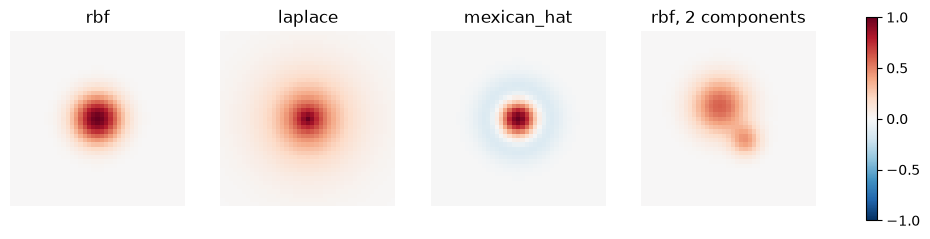

In [4]:
ax = np.arange(41.0)
R2 = np.stack(np.meshgrid(ax, ax, indexing="ij"), -1).reshape(-1, 2)
center = np.array([[[20.0, 20.0]]])
images = {
    name: component_factors(R2, center, [[30.0]], [[1.0]], name) for name in KERNELS
}
two = np.array([[[17.0, 18.0], [25.0, 24.0]]])
images["rbf, 2 components"] = component_factors(
    R2, two, [[40.0, 12.0]], [[0.6, 0.4]], "rbf"
)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for axis, (title, F) in zip(axes, images.items(), strict=True):
    img = axis.imshow(F.reshape(41, 41), cmap="RdBu_r", vmin=-1, vmax=1)
    axis.set_title(title)
    axis.axis("off")
fig.colorbar(img, ax=axes, shrink=0.8)
plt.show()

## 2. Synthetic data from each shape

`htfa.make_tfa_data` takes the same `kernel` and `n_components` options. Its centers and widths are drawn as for the RBF; with two components, the second component of each factor is offset from the first by about 0.75 sigma (per axis) and is 0.2 to 0.5 times as wide, and the mixing weights are drawn from a Dirichlet(3, 3) distribution. Each dataset has `K = 5` factors, 120 time points and Gaussian noise with standard deviation 0.3.

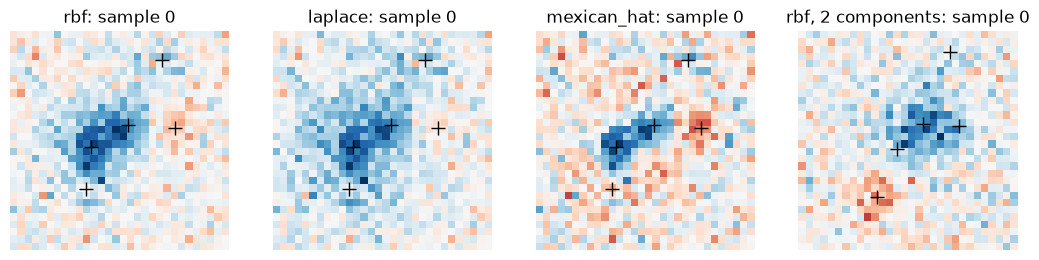

In [5]:
GRID, T, K, NOISE = (30, 30), 120, 5, 0.3
GENERATORS = {
    "rbf": dict(kernel="rbf"),
    "laplace": dict(kernel="laplace"),
    "mexican_hat": dict(kernel="mexican_hat"),
    "rbf, 2 components": dict(kernel="rbf", n_components=2),
}
data = {
    name: htfa.make_tfa_data(GRID, T, K=K, noise=NOISE, random_state=1, **options)
    for name, options in GENERATORS.items()
}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for axis, (name, (X, _, truth)) in zip(axes, data.items(), strict=True):
    lim = np.abs(X[:, 0]).max()
    axis.imshow(X[:, 0].reshape(GRID), cmap="RdBu_r", vmin=-lim, vmax=lim)
    axis.plot(truth["centers"][:, 1], truth["centers"][:, 0], "k+", ms=10)
    axis.set_title(f"{name}: sample 0")
    axis.axis("off")
plt.show()

## 3. Every kernel on every dataset, at `K = 5`

Each dataset is split in time: the first 60 samples are fitted, and the factors are then kept fixed while ridge weights are fitted to the other 60 samples. The training variance explained rises with the number of parameters; the held-out variance explained measures how well the fitted spatial factors, alone, describe new samples. The fitted kernels are the three shapes with one component and the RBF with two components (`n_components=2`), which has twice as many spatial parameters per factor plus a mixing weight.

The first row of each table, "true factors", fits ridge weights on the true factors: what a fit with the generating model and the true parameters would explain.

16 fits: 2.4 s in all, at most 0.27 s each


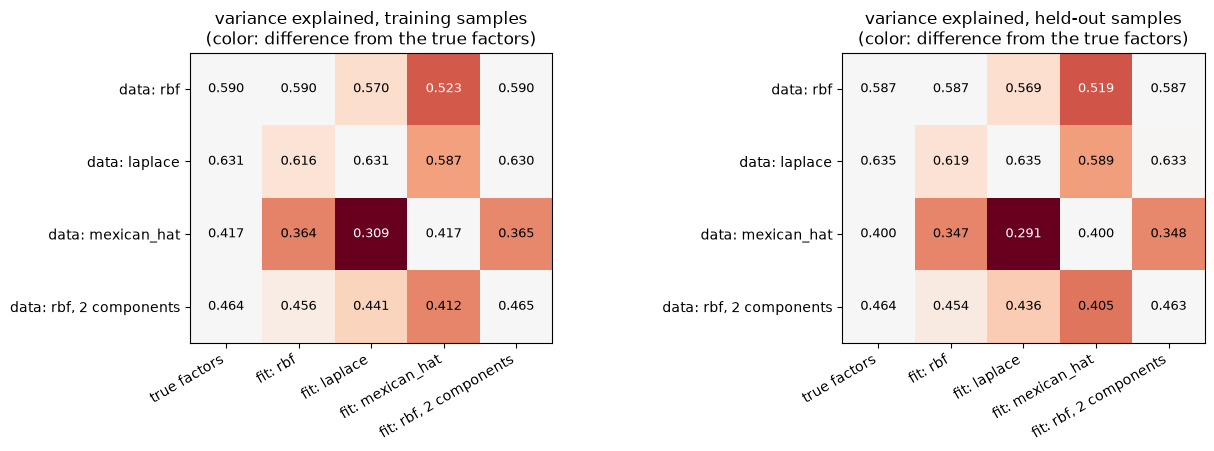

In [6]:
def r2(X, X_hat):
    """Variance explained: 1 - SS_residual / SS_total (about the grand mean)."""
    return 1 - np.sum((X - X_hat) ** 2) / np.sum((X - X.mean()) ** 2)


def held_out_r2(F, X):
    """Variance of X explained by fixed factors F with ridge weights (penalty
    var(X), as in the fits)."""
    W = np.linalg.solve(F.T @ F + np.var(X) * np.eye(F.shape[1]), F.T @ X)
    return r2(X, F @ W)


FITTED = GENERATORS
train, test = slice(0, T // 2), slice(T // 2, T)
names = list(GENERATORS)
fit_r2 = np.empty((len(names), len(FITTED) + 1))
test_r2 = np.empty_like(fit_r2)
fit_seconds = []
for i, gen in enumerate(names):
    X, R, truth = data[gen]
    F_true = component_factors(
        R,
        truth["component_centers"],
        truth["component_widths"],
        truth["mixing_weights"],
        truth["kernel"],
    )
    fit_r2[i, 0] = held_out_r2(F_true, X[:, train])
    test_r2[i, 0] = held_out_r2(F_true, X[:, test])
    for j, options in enumerate(FITTED.values(), start=1):
        t0 = time.perf_counter()
        model = htfa.TFA(K=K, standardize=False, random_state=0, **options).fit(
            X[:, train], R
        )
        fit_seconds.append(time.perf_counter() - t0)
        fit_r2[i, j] = r2(X[:, train], model.reconstruct())
        test_r2[i, j] = held_out_r2(model.factors(), X[:, test])
print(
    f"{len(fit_seconds)} fits: {np.sum(fit_seconds):.1f} s in all, "
    f"at most {np.max(fit_seconds):.2f} s each"
)

columns = ["true factors"] + [f"fit: {f}" for f in FITTED]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), constrained_layout=True)
panels = zip(axes, (fit_r2, test_r2), ("training", "held-out"), strict=True)
for axis, values, title in panels:
    # Each row relative to its own true-factor value, so rows are comparable.
    rel = values - values[:, :1]
    lim = np.abs(rel).max()
    axis.imshow(rel, cmap="RdBu", vmin=-lim, vmax=lim)
    for (a, b), v in np.ndenumerate(values):
        dark = abs(rel[a, b]) > 0.6 * lim
        axis.text(
            b,
            a,
            f"{v:.3f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if dark else "black",
        )
    axis.set_xticks(range(len(columns)), columns, rotation=30, ha="right")
    axis.set_yticks(range(len(names)), [f"data: {n}" for n in names])
    axis.set_title(
        f"variance explained, {title} samples\n"
        "(color: difference from the true factors)"
    )
plt.show()

In [7]:
# The same numbers as text: for each dataset, the fitted kernel with the
# highest held-out variance explained.
for i, gen in enumerate(names):
    j = 1 + int(np.argmax(test_r2[i, 1:]))
    print(
        f"data {gen:18s}: best held-out fit {columns[j]:24s} {test_r2[i, j]:.4f} "
        f"(true factors {test_r2[i, 0]:.4f})"
    )

data rbf               : best held-out fit fit: rbf                 0.5872 (true factors 0.5874)
data laplace           : best held-out fit fit: laplace             0.6346 (true factors 0.6347)
data mexican_hat       : best held-out fit fit: mexican_hat         0.3996 (true factors 0.3998)
data rbf, 2 components : best held-out fit fit: rbf, 2 components   0.4632 (true factors 0.4638)


On the training samples the two-component mixture always explains at least as much as the single RBF (it contains it), so it is the held-out columns that compare shapes. Each single-component kernel does best on data generated from its own shape; on the mixture data the two-component fit comes closest to the true factors.

## 4. Variance explained against `K`

The same fits for `K` from 2 to 8 factors (all 120 samples, training variance explained). The kernel that generated the data reaches the true factors' level at the true `K = 5` and stays there. On the mexican hat data the other kernels keep rising past `K = 5`: they use their extra factors for the negative surrounds.

K sweep: 96 fits in 15.0 s


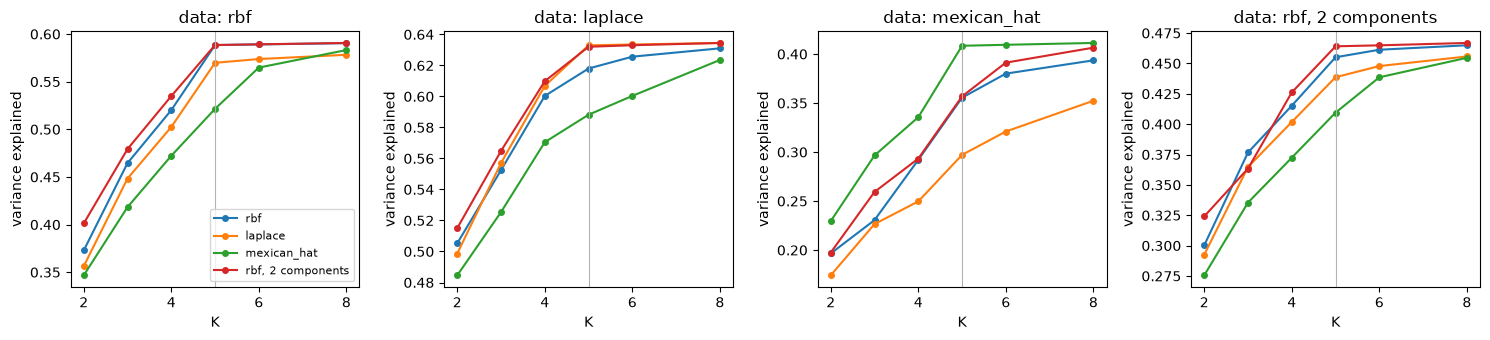

In [8]:
Ks = [2, 3, 4, 5, 6, 8]
sweep = {}
t0 = time.perf_counter()
for gen in names:
    X, R, _ = data[gen]
    for fitted, options in FITTED.items():
        sweep[gen, fitted] = [
            r2(
                X,
                htfa.TFA(K=k, standardize=False, random_state=0, **options)
                .fit(X, R)
                .reconstruct(),
            )
            for k in Ks
        ]
n_fits = len(names) * len(FITTED) * len(Ks)
print(f"K sweep: {n_fits} fits in {time.perf_counter() - t0:.1f} s")
fig, axes = plt.subplots(1, len(names), figsize=(15, 3.5), sharey=False)
for axis, gen in zip(axes, names, strict=True):
    for fitted in FITTED:
        axis.plot(Ks, sweep[gen, fitted], "o-", ms=4, label=fitted)
    axis.axvline(K, color="0.7", lw=0.8)
    axis.set(title=f"data: {gen}", xlabel="K", ylabel="variance explained")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Variance explained against `n_components`

The two-component RBF data, fitted with RBF mixtures of 1 to 4 components at `K = 5`: the training variance explained (which can only rise with more components when the fit finds its optimum) and the held-out variance explained of the fitted factors. Two components reach the held-out value of the true factors; three and four add nothing on the held-out samples.

n_components=1: training 0.4561, held-out 0.4537
n_components=2: training 0.4646, held-out 0.4632
n_components=3: training 0.4647, held-out 0.4632
n_components=4: training 0.4648, held-out 0.4632


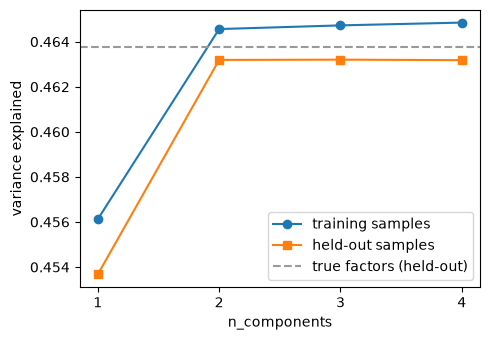

In [9]:
X, R, truth = data["rbf, 2 components"]
Ms = [1, 2, 3, 4]
by_m = []
for M in Ms:
    model = htfa.TFA(K=K, n_components=M, standardize=False, random_state=0).fit(
        X[:, train], R
    )
    by_m.append(
        (r2(X[:, train], model.reconstruct()), held_out_r2(model.factors(), X[:, test]))
    )
by_m = np.array(by_m)
for M, (a, b) in zip(Ms, by_m, strict=True):
    print(f"n_components={M}: training {a:.4f}, held-out {b:.4f}")
fig, axis = plt.subplots(figsize=(5, 3.5))
axis.plot(Ms, by_m[:, 0], "o-", label="training samples")
axis.plot(Ms, by_m[:, 1], "s-", label="held-out samples")
axis.axhline(
    test_r2[names.index("rbf, 2 components"), 0],
    color="0.6",
    ls="--",
    label="true factors (held-out)",
)
axis.set(xlabel="n_components", ylabel="variance explained", xticks=Ms)
axis.legend()
plt.tight_layout()
plt.show()

## 6. The fitted components

A fit with `n_components > 1` reports each factor's components (`component_centers_`, `component_widths_`, `mixing_weights_`) as well as a summary center and width per factor (`centers_`, `widths_`: their averages weighted by the mixing weights). Below, the two-component fit to the mixture data: true components as crosses, fitted ones as circles, with marker area proportional to the mixing weight.

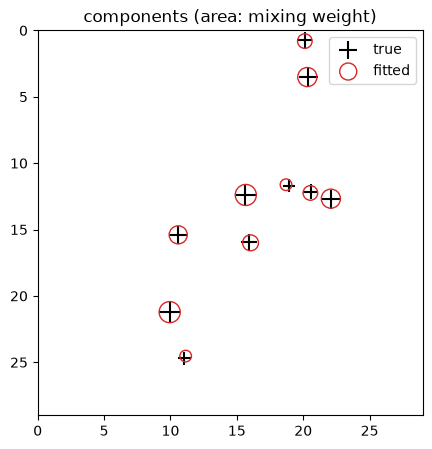

fitted mixing weights:
 [[0.63 0.37]
 [0.44 0.56]
 [0.63 0.37]
 [0.77 0.23]
 [0.23 0.77]]
total run time: 20.6 s


In [10]:
model = htfa.TFA(K=K, n_components=2, standardize=False, random_state=0).fit(X, R)
fig, axis = plt.subplots(figsize=(5, 5))
tc, tp = truth["component_centers"], truth["mixing_weights"]
fc, fp = model.component_centers_, model.mixing_weights_
axis.scatter(
    tc[..., 1].ravel(),
    tc[..., 0].ravel(),
    s=300 * tp.ravel(),
    marker="+",
    c="k",
    label="true",
)
axis.scatter(
    fc[..., 1].ravel(),
    fc[..., 0].ravel(),
    s=300 * fp.ravel(),
    facecolors="none",
    edgecolors="C3",
    label="fitted",
)
axis.set(
    xlim=(0, 29), ylim=(29, 0), aspect="equal", title="components (area: mixing weight)"
)
axis.legend()
plt.show()
print("fitted mixing weights:\n", np.round(model.mixing_weights_, 2))
print(f"total run time: {time.perf_counter() - start_time:.1f} s")

## 7. Component lobes and network connections

A mixture is one factor with several spatial components. The default network
view draws every component separately. If factors A and B are connected, every
component of A connects to every component of B with the **same edge value**.
There are no added connections between components within one factor. The
mixing weights affect spatial-lobe opacity, not the connectivity values.

Non-RBF kernels keep their profiles: a Mexican-hat component has a positive
core and a negative surround. BrainNet draws their 5%-of-peak isosurfaces
(orange and teal below); nilearn shows signed maximum-absolute projections
(red and blue). Negative BrainNet shells are more transparent so that their
cores remain visible. These spatial signs are separate from connection signs.
The display shows the individual weighted components, not their potentially
cancelling sum. Mask resolution and occlusion limit what is visible; a spin
or other projections help inspect overlapping lobes.

`node_mode="summary"` restores one sphere/centroid per factor. Single RBFs
retain that summary view by default; `node_mode="components"` also works for
them. The same options work for group templates (`group=...`) and animations.


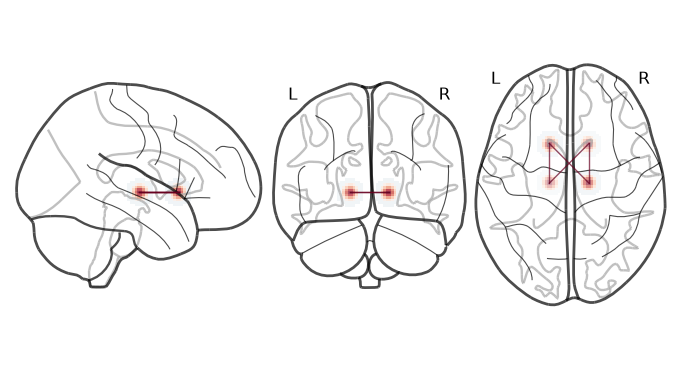

In [11]:
# A small 3D example, initialized at known components so their separation
# is easy to see. All plots use the fitted model, including fitted mixing weights.
a = np.arange(-30.0, 31.0, 2.0)
R3 = np.stack(np.meshgrid(a, a, a, indexing="ij"), -1).reshape(-1, 3)
C3 = np.array(
    [[[-15.0, -15.0, 0.0], [15.0, -15.0, 0.0]], [[-15.0, 15.0, 0.0], [15.0, 15.0, 0.0]]]
)
w3 = np.full((2, 2), 40.0)
pi3 = np.array([[0.3, 0.7], [0.6, 0.4]])
W3 = np.random.default_rng(1).normal(size=(2, 30))
W3[1] = 0.7 * W3[0] + 0.7 * W3[1]
X3 = component_factors(R3, C3, w3, pi3, "mexican_hat") @ W3
model3 = htfa.TFA(
    K=2,
    kernel="mexican_hat",
    n_components=2,
    standardize=False,
    max_iter=5,
    random_state=0,
)
model3.fit(X3, R3, start=(C3, w3, pi3))
res3 = htfa.HTFAResults(model3, htfa.load(X3, coords=R3))
res3.plot_connectivity(subject=0, threshold=0.0, snap=False)

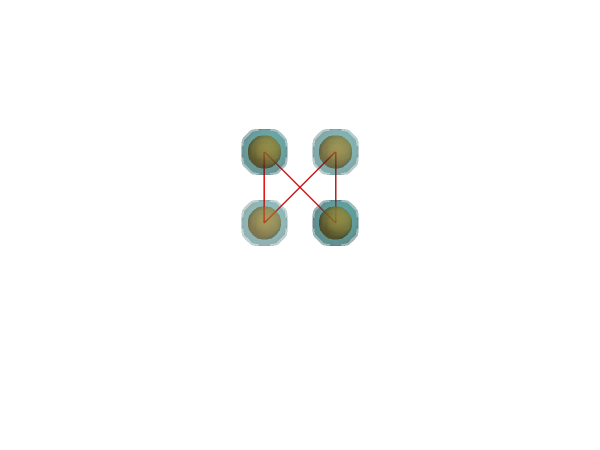

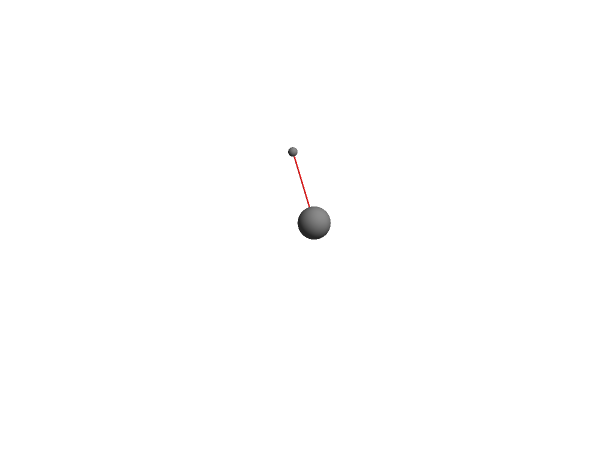

In [12]:
from IPython.display import display

display(
    res3.plot_network(
        subject=0,
        mesh=None,
        snap=False,
        view="dorsal",
        node_color="darkorange",
        size=(600, 450),
    )
)
display(
    res3.plot_network(
        subject=0,
        mesh=None,
        snap=False,
        view="dorsal",
        node_mode="summary",
        size=(600, 450),
    )
)
# Animation uses the same lobes and repeated edges:
# res3.animate_network("components.gif", subject=0, window=10,
#                      spin=(0, 0, 1), duration=4, mesh=None)

## Notes

- HTFA takes the same options; its template then holds every component's center and width, and the mixing weights, each with a prior as for the widths (see `htfa.HTFA`).
- The summary plots in `htfa.HTFAResults` and `htfa.plot_network` with `node_mode="summary"` place each node at the in-brain centroid of its own profile (the positive part for the mexican hat); see `htfa.brainnet.effective_nodes`.
- With more components a factor has more ways to fit the same data: components of one factor can trade places or overlap, so their individual parameters are only identified when the components are distinct (well separated or of clearly different widths).